# Step 2: Exploratory Data Analysis (EDA)

**Client:** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Business goal:** prioritize which objects follow-up telescopes should re-observe, under a "zero false negative" policy.

This step describes the data **before any modeling**. It must answer four questions:

1. Are the two files reliable, and can they be joined?
2. Which variables are actually measured, and which are derived from other columns?
3. Can the candidate targets (`pha`, future dangerous approach) be used without data leakage?
4. Which observational biases must we keep in mind for steps 3 to 7?

Figures are saved in `nasa-project/reports/02_eda/` (versioned, unlike `data/`) so they can be reused in the slides.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# The notebook can be run from the repo root, from nasa-project/ or from notebooks/
def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Folder nasa-project/data/raw not found.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
REPORT_DIR = PROJECT_DIR / "reports" / "02_eda"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREY, RED = "#2878B5", "#E07A2D", "#8C8C8C", "#C0392B"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}"

LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
LUNAR_DISTANCE_AU = 0.00257  # 1 lunar distance ≈ 384,400 km
print("Raw data:", sorted(p.name for p in RAW_DIR.glob("*.csv")))

Raw data: ['asteroid_close_approaches_2015_2035 (1).csv', 'near_earth_asteroids_2025 (1).csv']


## 1. Loading and schema check

In [2]:
def find_dataset(pattern: str) -> Path:
    matches = sorted(RAW_DIR.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(f"{len(matches)} file(s) matching {pattern!r} in {RAW_DIR}")
    return matches[0]

asteroids = pd.read_csv(find_dataset("near_earth_asteroids_2025*.csv"), low_memory=False)
approaches = pd.read_csv(find_dataset("asteroid_close_approaches_2015_2035*.csv"), low_memory=False)

expected_ast = {"pdes", "pha", "H", "diameter_km", "diameter_is_estimated", "albedo",
                "moid_au", "a", "e", "i", "q", "class", "first_obs"}
expected_app = {"designation", "close_approach_date", "distance_au", "dist_lunar",
                "velocity_km_s", "absolute_magnitude", "is_future"}
assert expected_ast <= set(asteroids.columns), expected_ast - set(asteroids.columns)
assert expected_app <= set(approaches.columns), expected_app - set(approaches.columns)

asteroids["first_obs"] = pd.to_datetime(asteroids["first_obs"], errors="coerce")
approaches["date"] = pd.to_datetime(approaches["close_approach_date"], errors="coerce")
assert approaches["date"].notna().all(), "Invalid approach dates"

print(f"Catalogue : {fmt(len(asteroids))} objects × {asteroids.shape[1]} columns")
print(f"Approaches: {fmt(len(approaches))} events × {approaches.shape[1]} columns")

Catalogue : 41,281 objects × 29 columns
Approaches: 27,430 events × 14 columns


In [3]:
asteroids.head(3)

,spkid,full_name,pdes,name,pha,H,diameter_km,diameter_m,diameter_is_estimated,size_category,albedo,rot_per,class,e,a,i,q,ad,per,per_y,moid_au,moid_km,moid_lunar_distances,n,condition_code,first_obs,last_obs,data_arc,data_arc_years
0,20000433,433 Eros (A898 PA),433,Eros,False,10.390,16.840,"16,840.000",False,Large (>1 km) — City killer+,0.250,5.270,AMO,0.223,1.458,10.830,1.133,1.780,643.000,1.760,0.148,"22,140,485.000",57.600,0.560,0.000,1893-10-29,2021-05-13,"46,582.000",127.530
1,20000719,719 Albert (A911 TB),719,Albert,False,15.590,2.707,"2,706.800",True,Large (>1 km) — City killer+,NaN,5.801,AMO,0.547,2.637,11.570,1.195,4.080,"1,560.000",4.280,0.201,"30,069,172.000",78.220,0.230,0.000,1911-10-04,2026-03-20,"41,806.000",114.460
2,20000887,887 Alinda (A918 AA),887,Alinda,False,13.820,4.200,"4,200.000",False,Large (>1 km) — City killer+,0.310,28.410,AMO,0.571,2.474,9.400,1.061,3.890,"1,420.000",3.890,0.080,"11,922,950.000",31.020,0.253,0.000,1918-02-09,2025-08-27,"39,281.000",107.550


In [4]:
approaches.head(3)

,designation,full_name,close_approach_date,distance_au,dist_km,dist_lunar,distance_min_au,distance_max_au,velocity_km_s,v_rel_kmh,velocity_infinity_km_s,absolute_magnitude,is_future,date
0,2022 AP1,(2022 AP1),2015-01-01 00:27,0.045,"6,746,806.000",17.550,0.014,0.077,11.892,"42,810.000",11.887,28.390,False,2015-01-01 00:27:00
1,2015 AE45,(2015 AE45),2015-01-02 15:56,0.048,"7,216,474.000",18.770,0.048,0.048,7.066,"25,436.000",7.058,25.300,False,2015-01-02 15:56:00
2,613286,613286 (2005 YQ96),2015-01-02 21:46,0.027,"3,967,664.000",10.320,0.027,0.027,12.703,"45,732.000",12.695,20.630,False,2015-01-02 21:46:00


## 2. Data quality and join

We check for duplicates, the join key (`designation` ↔ `pdes`) and the consistency of the absolute magnitude H between the two tables.

In [5]:
catalogue_ids = set(asteroids["pdes"].astype(str))
in_catalogue = approaches["designation"].astype(str).isin(catalogue_ids)
h_check = approaches.merge(asteroids[["pdes", "H"]], left_on="designation", right_on="pdes", how="inner")

quality = pd.DataFrame({
    "check": [
        "Duplicate pdes (catalogue)",
        "Duplicate designation + date (approaches)",
        "Approaches matched to the catalogue",
        "Distinct objects in the approaches",
        "Max |H catalogue − H approaches|",
        "Approach date range",
    ],
    "result": [
        fmt(asteroids["pdes"].duplicated().sum()),
        fmt(approaches.duplicated(["designation", "close_approach_date"]).sum()),
        f"{in_catalogue.mean():.2%} ({fmt((~in_catalogue).sum())} unmatched)",
        fmt(approaches["designation"].nunique()),
        f"{(h_check['H'] - h_check['absolute_magnitude']).abs().max():.3f}",
        f"{approaches['date'].min():%Y-%m-%d} → {approaches['date'].max():%Y-%m-%d}",
    ],
})
quality.to_csv(REPORT_DIR / "quality_checks.csv", index=False)
quality

,check,result
0,Duplicate pdes (catalogue),0
1,Duplicate designation + date (approaches),0
2,Approaches matched to the catalogue,99.97% (8 unmatched)
3,Distinct objects in the approaches,"20,886"
4,Max |H catalogue − H approaches|,0.005
5,Approach date range,2015-01-01 → 2035-12-29


**Reading:** no duplicates, the join is almost perfect and H is identical in both tables. The two files can be joined without loss.

## 3. Missing values: the diameter trap

At first glance, `diameter_km` has **no** missing values. But the `diameter_is_estimated` column shows that most diameters are not measured: they are computed from H. These values must therefore be counted as diameters that are *actually* unknown.

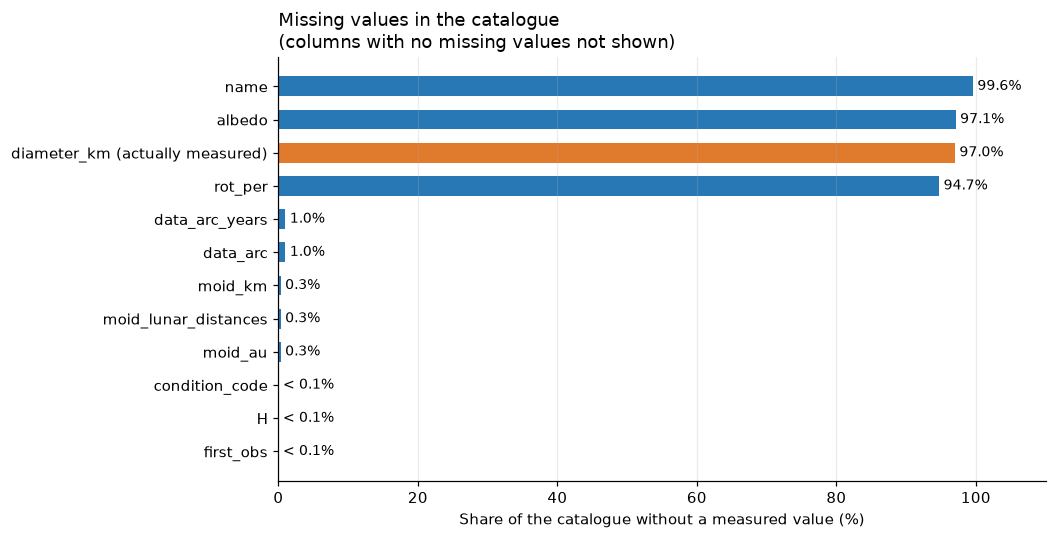

In [6]:
missing = asteroids.isna().mean().mul(100)
missing["diameter_km (actually measured)"] = asteroids["diameter_is_estimated"].mean() * 100
missing = missing[missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
colors = [ORANGE if "diameter" in c else BLUE for c in missing.index]
bars = ax.barh(missing.index, missing.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" if v >= 0.1 else "< 0.1%" for v in missing.values], padding=3, fontsize=9)
ax.set_xlabel("Share of the catalogue without a measured value (%)")
ax.set_xlim(0, 110)
ax.set_title("Missing values in the catalogue\n(columns with no missing values not shown)", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "missing_values")
plt.show()

missing.rename("missing_percent").to_frame().sort_values(
    "missing_percent", ascending=False).to_csv(REPORT_DIR / "missing_values.csv")

In [7]:
# Do the "estimated" diameters exactly follow the formula D = 1329 / √albedo × 10^(−H/5)?
est = asteroids[asteroids["diameter_is_estimated"]]
implied_albedo = (1329 * 10 ** (-est["H"] / 5) / est["diameter_km"]) ** 2
print(f"Implied albedo of the estimated diameters: mean {implied_albedo.mean():.4f}, "
      f"std {implied_albedo.std():.1e}")

measured = asteroids[~asteroids["diameter_is_estimated"]]
print(f"Actually measured diameters: {fmt(len(measured))} objects "
      f"({len(measured) / len(asteroids):.1%}), {measured['albedo'].notna().mean():.0%} of them with an albedo")

Implied albedo of the estimated diameters: mean 0.1400, std 2.8e-17
Actually measured diameters: 1,246 objects (3.0%), 96% of them with an albedo


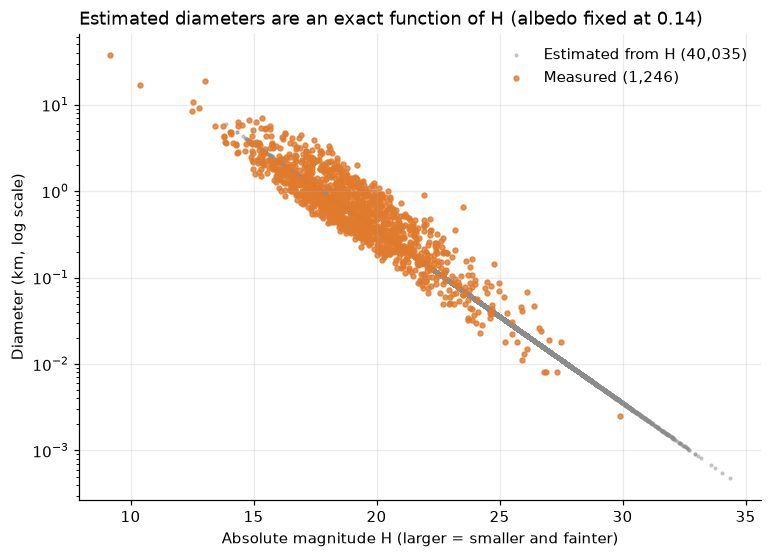

In [8]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(est["H"], est["diameter_km"], s=3, color=GREY, alpha=0.4,
           label=f"Estimated from H ({fmt(len(est))})", rasterized=True)
ax.scatter(measured["H"], measured["diameter_km"], s=10, color=ORANGE, alpha=0.8,
           label=f"Measured ({fmt(len(measured))})")
ax.set_yscale("log")
ax.set_xlabel("Absolute magnitude H (larger = smaller and fainter)")
ax.set_ylabel("Diameter (km, log scale)")
ax.set_title("Estimated diameters are an exact function of H (albedo fixed at 0.14)", loc="left")
ax.legend(frameon=False)
save(fig, "measured_vs_estimated_diameter")
plt.show()

**Consequences for the next steps:**

- **97% of the diameters are computed from H with a fixed albedo of 0.14.** For these objects, `diameter_km` carries no information beyond H.
- **Step 4 (diameter regression):** the model must be trained and evaluated **only on the ~1,250 measured diameters**. Otherwise it relearns the formula and reaches a meaningless R² ≈ 1.
- `size_category` is derived from the diameter, hence from H. It has the same problem.
- The albedo is missing for 97% of the objects, so it cannot be used directly as a feature across the catalogue.

## 4. Catalogue distributions

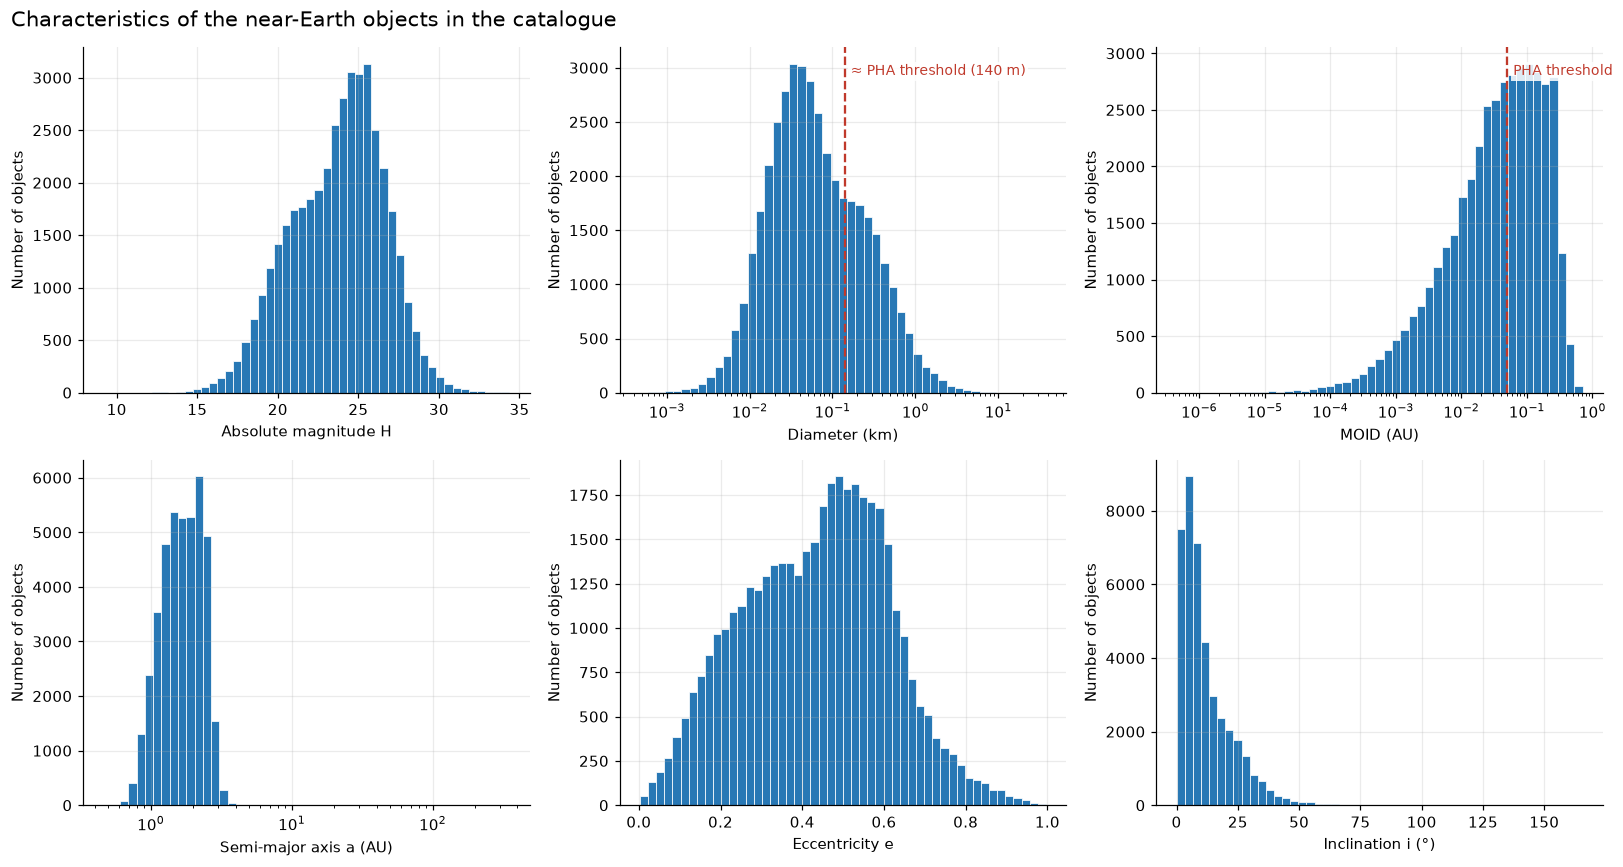

In [9]:
specs = [
    ("H", "Absolute magnitude H", False, None),
    ("diameter_km", "Diameter (km)", True, 0.14),
    ("moid_au", "MOID (AU)", True, 0.05),
    ("a", "Semi-major axis a (AU)", True, None),
    ("e", "Eccentricity e", False, None),
    ("i", "Inclination i (°)", False, None),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, label, log, ref) in zip(axes.flat, specs):
    v = asteroids[col].dropna()
    v = v[v > 0] if log else v
    bins = np.logspace(np.log10(v.min()), np.log10(v.max()), 50) if log else 50
    ax.hist(v, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    if log:
        ax.set_xscale("log")
    if ref is not None:
        ax.axvline(ref, color=RED, ls="--", lw=1.5)
        ax.annotate("PHA threshold" if col == "moid_au" else "≈ PHA threshold (140 m)",
                    xy=(ref, 0.92), xycoords=("data", "axes fraction"),
                    xytext=(4, 0), textcoords="offset points", color=RED, fontsize=9, bbox=LABEL_BOX)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of objects")
fig.suptitle("Characteristics of the near-Earth objects in the catalogue", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
save(fig, "catalogue_distributions")
plt.show()

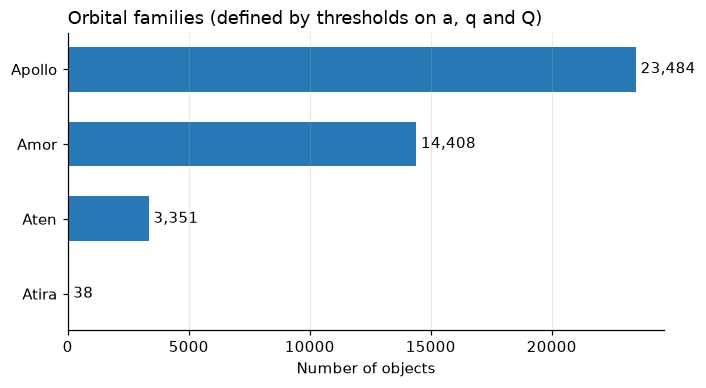

In [10]:
cls = (asteroids["class"].value_counts()
       .rename({"APO": "Apollo", "AMO": "Amor", "ATE": "Aten", "IEO": "Atira"}))
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(cls.index[::-1], cls.values[::-1], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[fmt(v) for v in cls.values[::-1]], padding=3)
ax.set_xlabel("Number of objects")
ax.set_title("Orbital families (defined by thresholds on a, q and Q)", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "orbital_families")
plt.show()

## 5. The `pha` target: class imbalance and data leakage

An object is classified as a **PHA** (Potentially Hazardous Asteroid) if **MOID ≤ 0.05 AU and H ≤ 22**. We check whether the label in the file follows this rule.

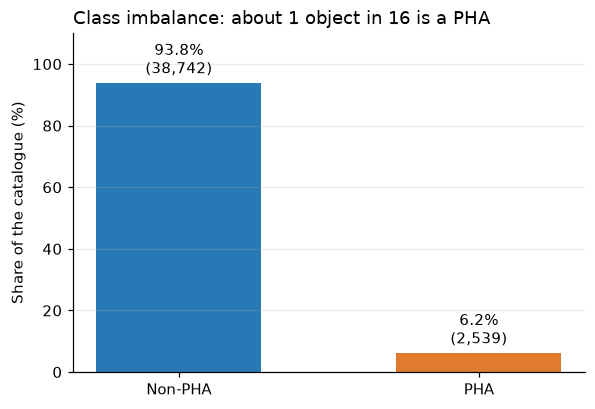

In [11]:
counts = asteroids["pha"].value_counts().reindex([False, True])
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Non-PHA", "PHA"], pct.values, color=[BLUE, ORANGE], width=0.55)
ax.bar_label(bars, labels=[f"{p:.1f}%\n({fmt(c)})" for p, c in zip(pct, counts)], padding=3)
ax.set_ylabel("Share of the catalogue (%)")
ax.set_ylim(0, 110)
ax.set_title("Class imbalance: about 1 object in 16 is a PHA", loc="left")
ax.grid(axis="x", visible=False)
save(fig, "pha_class_balance")
plt.show()

pd.DataFrame({"count": counts, "percent": pct}).to_csv(REPORT_DIR / "pha_class_balance.csv")

In [12]:
rule = (asteroids["moid_au"] <= 0.05) & (asteroids["H"] <= 22)
agreement = (rule == asteroids["pha"]).mean()
print(f"The pha label matches the rule (MOID ≤ 0.05 and H ≤ 22) for {agreement:.2%} of the objects.")
pd.crosstab(asteroids["pha"], rule, rownames=["pha (file)"], colnames=["MOID/H rule"])

The pha label matches the rule (MOID ≤ 0.05 and H ≤ 22) for 99.86% of the objects.


MOID/H rule,False,True
pha (file),,
False,38722,20
True,36,2503


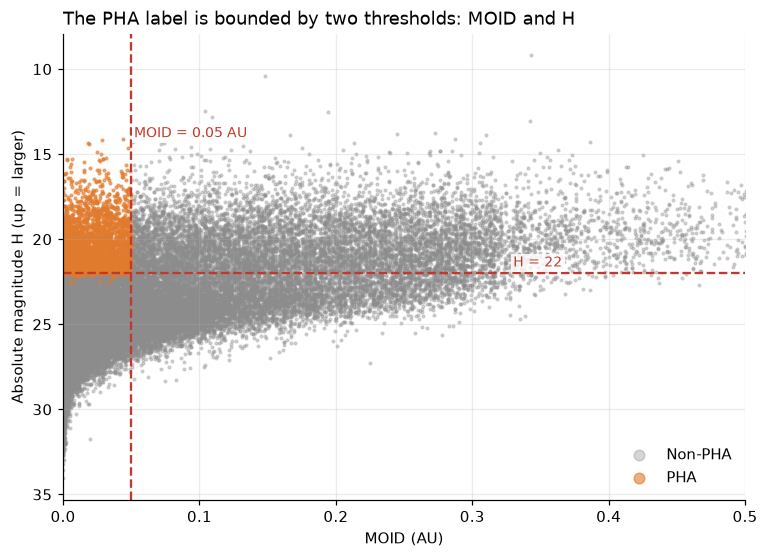

In [13]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for flag, color, label in [(False, GREY, "Non-PHA"), (True, ORANGE, "PHA")]:
    d = asteroids[asteroids["pha"] == flag]
    ax.scatter(d["moid_au"], d["H"], s=3, alpha=0.35 if not flag else 0.6,
               color=color, label=label, rasterized=True)
ax.axvline(0.05, color=RED, ls="--", lw=1.5)
ax.axhline(22, color=RED, ls="--", lw=1.5)
ax.text(0.052, 14, "MOID = 0.05 AU", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.text(0.33, 21.6, "H = 22", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlim(0, 0.5)
ax.invert_yaxis()
ax.set_xlabel("MOID (AU)")
ax.set_ylabel("Absolute magnitude H (up = larger)")
ax.set_title("The PHA label is bounded by two thresholds: MOID and H", loc="left")
ax.legend(frameon=False, markerscale=4, loc="lower right")
save(fig, "pha_leakage_moid_h")
plt.show()

**Consequence (pillar 2, leakage prevention):** `pha` is almost a deterministic function of MOID and H. A model given these two variables would reach a recall close to 100% without learning anything. For the step 5 classification, we must **remove `moid_au`, `moid_km`, `moid_lunar_distances`, `H` and every column derived from H** (`diameter_*`, `size_category`), or choose another target.

## 6. Approach distributions

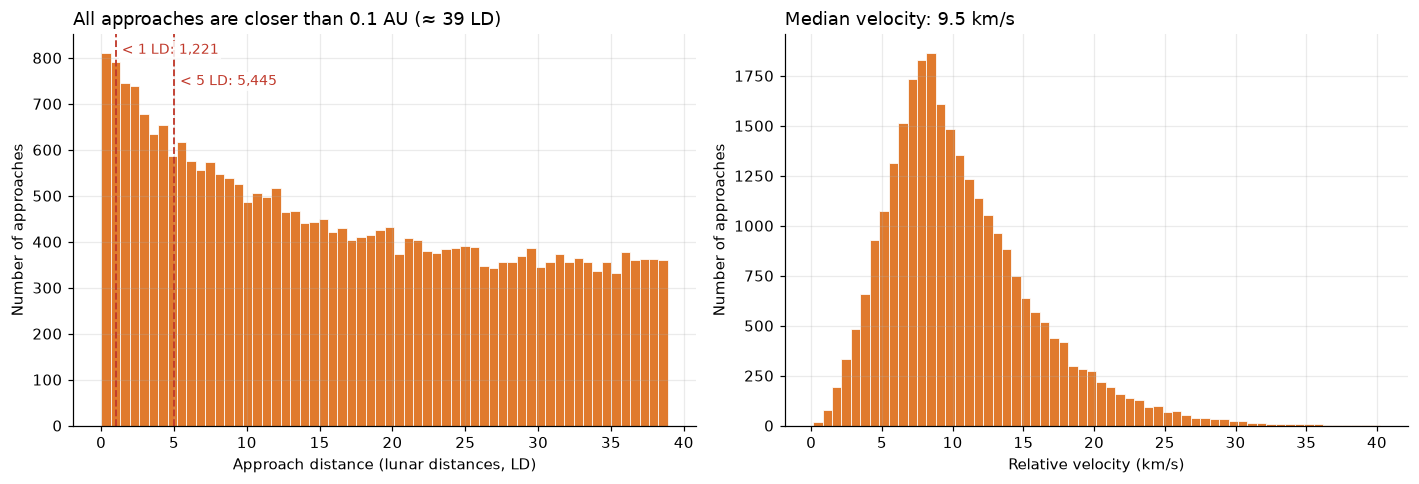

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.hist(approaches["dist_lunar"], bins=60, color=ORANGE, edgecolor="white", linewidth=0.5)
for ld in (1, 5):
    n = (approaches["dist_lunar"] < ld).sum()
    ax.axvline(ld, color=RED, ls="--", lw=1.2)
    ax.annotate(f"< {ld} LD: {fmt(n)}", xy=(ld, 0.95 - 0.08 * (ld == 5)),
                xycoords=("data", "axes fraction"), xytext=(4, 0),
                textcoords="offset points", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Approach distance (lunar distances, LD)")
ax.set_ylabel("Number of approaches")
ax.set_title("All approaches are closer than 0.1 AU (≈ 39 LD)", loc="left")

ax = axes[1]
ax.hist(approaches["velocity_km_s"], bins=60, color=ORANGE, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Relative velocity (km/s)")
ax.set_ylabel("Number of approaches")
ax.set_title(f"Median velocity: {approaches['velocity_km_s'].median():.1f} km/s", loc="left")

fig.tight_layout()
save(fig, "approach_distributions")
plt.show()

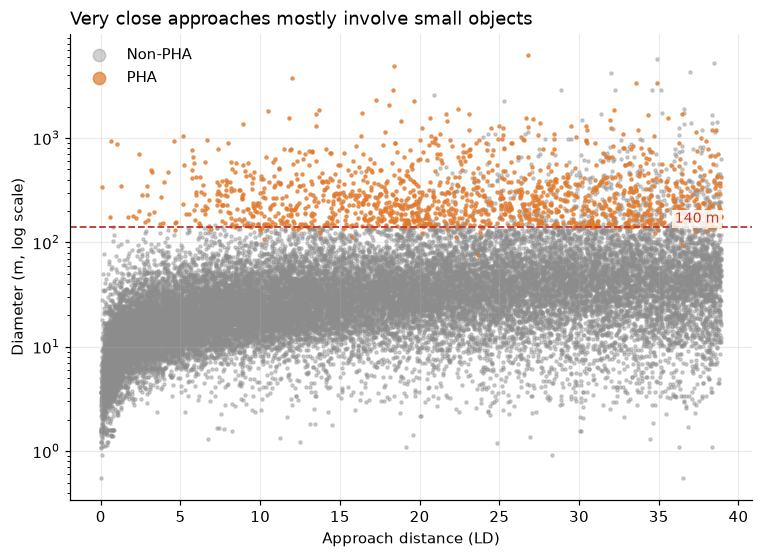

Share of approaches made by PHAs: 5.0%
Median diameter of approaching objects: 27 m


In [15]:
merged = approaches.merge(
    asteroids[["pdes", "pha", "diameter_km", "diameter_is_estimated", "first_obs"]],
    left_on="designation", right_on="pdes", how="left")

fig, ax = plt.subplots(figsize=(8, 5.5))
for flag, color, label in [(False, GREY, "Non-PHA"), (True, ORANGE, "PHA")]:
    d = merged[merged["pha"] == flag]
    ax.scatter(d["dist_lunar"], d["diameter_km"] * 1000, s=4, alpha=0.4 if not flag else 0.7,
               color=color, label=label, rasterized=True)
ax.axhline(140, color=RED, ls="--", lw=1.2)
ax.text(36, 155, "140 m", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_yscale("log")
ax.set_xlabel("Approach distance (LD)")
ax.set_ylabel("Diameter (m, log scale)")
ax.set_title("Very close approaches mostly involve small objects", loc="left")
ax.legend(frameon=False, markerscale=4)
save(fig, "approach_distance_vs_size")
plt.show()

print(f"Share of approaches made by PHAs: {merged['pha'].mean():.1%}")
print(f"Median diameter of approaching objects: {merged['diameter_km'].median() * 1000:.0f} m")

## 7. Observational bias over time

The approach file covers 2015–2035. Yet future approaches are only known for objects that have **already been discovered**. We therefore compare the number of approaches per year with the number of discoveries per year.

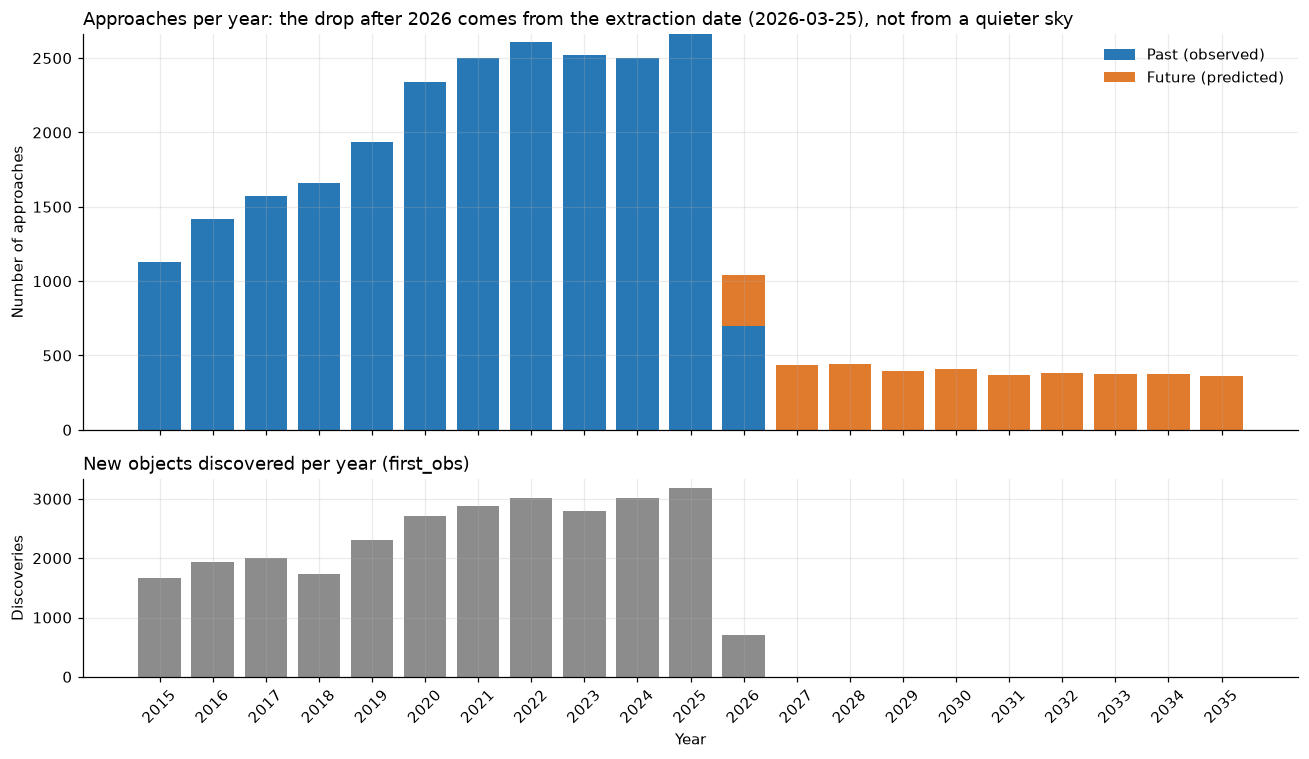

In [16]:
cutoff = approaches.loc[approaches["is_future"], "date"].min()
years = range(2015, 2036)
by_year = approaches.groupby([approaches["date"].dt.year, "is_future"]).size().unstack(fill_value=0)
by_year = by_year.reindex(years, fill_value=0)
discoveries = asteroids["first_obs"].dt.year.value_counts().reindex(years, fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
ax.bar(by_year.index, by_year[False], color=BLUE, label="Past (observed)")
ax.bar(by_year.index, by_year[True], bottom=by_year[False], color=ORANGE, label="Future (predicted)")
ax.set_ylabel("Number of approaches")
ax.set_title(f"Approaches per year: the drop after 2026 comes from the extraction date "
             f"({cutoff:%Y-%m-%d}), not from a quieter sky", loc="left")
ax.legend(frameon=False)

ax = axes[1]
ax.bar(discoveries.index, discoveries.values, color=GREY)
ax.set_ylabel("Discoveries")
ax.set_xlabel("Year")
ax.set_title("New objects discovered per year (first_obs)", loc="left")
ax.set_xticks(list(years))
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
save(fig, "approaches_per_year_bias")
plt.show()

by_year.rename(columns={False: "past", True: "future"}).assign(
    discoveries=discoveries).to_csv(REPORT_DIR / "approaches_per_year.csv")

In [17]:
before_discovery = (merged["date"] < merged["first_obs"]).mean()
per_object = approaches["designation"].value_counts()
print(f"Approaches that happened BEFORE the object was discovered: {before_discovery:.1%}")
print(f"Approaches per object: median {per_object.median():.0f}, "
      f"{(per_object == 1).mean():.0%} of the objects have a single approach, max {per_object.max()}")

Approaches that happened BEFORE the object was discovered: 34.1%
Approaches per object: median 1, 80% of the objects have a single approach, max 21


**Reading:**

- **The increase from 2015 to 2025 follows the increase in discoveries.** It reflects survey capacity, not a real increase in the number of approaches.
- **The drop after March 2026** is explained by the absence, in the predictions, of objects that have not been discovered yet.
- **About a third of the past approaches happened before the object was discovered.** They were reconstructed afterwards.
- **Most objects have a single approach** in the window. Features such as "history of past approaches" would therefore be empty for most of the catalogue.

These points will guide the choice of target in step 3 and keep the conclusions presented to the PDCO cautious.

## 8. Summary and implications for the next steps

In [18]:
summary = pd.DataFrame({
    "finding": [
        "Objects in the catalogue",
        "Share of PHAs",
        "Agreement between the pha label and the MOID/H rule",
        "Actually measured diameters",
        "Approach events (2015–2035)",
        "Approaches closer than 1 LD",
        "Future approaches (after extraction)",
        "Objects with a single approach",
    ],
    "value": [
        fmt(len(asteroids)),
        f"{asteroids['pha'].mean():.1%}",
        f"{agreement:.1%}",
        f"{fmt(len(measured))} ({len(measured) / len(asteroids):.1%})",
        fmt(len(approaches)),
        fmt((approaches['dist_lunar'] < 1).sum()),
        fmt(approaches['is_future'].sum()),
        f"{(per_object == 1).mean():.0%}",
    ],
})
summary.to_csv(REPORT_DIR / "eda_summary.csv", index=False)
summary

,finding,value
0,Objects in the catalogue,"41,281"
1,Share of PHAs,6.2%
2,Agreement between the pha label and the MOID/H...,99.9%
3,Actually measured diameters,"1,246 (3.0%)"
4,Approach events (2015–2035),"27,430"
5,Approaches closer than 1 LD,"1,221"
6,Future approaches (after extraction),"3,888"
7,Objects with a single approach,80%


| Finding | Decision for the next steps |
|---|---|
| `pha` ≈ rule on MOID and H | Step 5: exclude MOID, H and the columns derived from H if `pha` is the target |
| 97% of diameters = formula applied to H | Step 4: train and evaluate the regression **only on measured diameters** |
| 6% of PHAs | `class_weight="balanced"`, stratified split, recall / F1 / PR-AUC instead of accuracy |
| Discovery bias and extraction date | Step 3: explicit temporal split if a target uses approaches, and caution with yearly trends |
| A single approach for most objects | Approach-history features are weakly informative: favor orbital elements (a, e, i, q, ad, period) |
| Orbital families defined by thresholds | Step 6: do not present clustering as a rediscovery of Apollo, Aten, Amor and Atira; look for risk profiles instead |